---
title: "Plume vetting: a spectral test for matched-filter candidates"
---

# Plume vetting: a spectral test for matched-filter candidates

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/plumax/blob/main/docs/notebooks/vetting/01_vetting_one_scene.ipynb)

The matched filter scores each pixel by one projection of its spectrum, so anything that removes light under methane's 2.3 μm band scores: carbonate soils, salt pans, shadows, striping. Plume vetting (Xiang et al. 2024; Růžička et al. 2026) goes back to the radiances. It pairs a candidate's strongest pixels with pixels outside it that have the same surface, divides them, and fits methane's transmittance times a smooth continuum to the ratio; the misfit $D_{\text{norm}}$ accepts or rejects the candidate. This notebook builds one EMIT-like scene in which the matched filter scores a carbonate patch above a real plume, and vets both.

The work comes from two packages. [`plumax.vetting`](xref:api#plumax.vetting) works on plume candidates: their seeds and background pool, the null over the plume's shape, and one call that vets a candidate. radtrax's `radtrax.retrieval.absorption` is the plume-agnostic [absorption-shape test](https://jejjohnson.github.io/radtrax/absorption-test/) those pieces run: the gas's window and transmittance, the pairing of two pixel sets, the ratio, the fit and $D_{\text{norm}}$. Every function below is imported from one of the two; the theory is on the [plume vetting](../../theory/plume_vetting.md) page.

**What you'll learn:**

1. How to get the transmittance the fit needs from radtrax's `ForwardModel`, and why a constant absorption coefficient biases the column low.
2. How seeds, one-to-one pairing and the ratio spectrum cancel the surface.
3. How the profile fit and $D_{\text{norm}}$ separate a plume from a confounder, and how a null from the same scene calibrates the score.

## Background

For a pixel under a plume and a pixel outside it with the same surface, sun and atmosphere, the ratio of their radiances cancels everything but the plume and what the two surfaces do not share:

$$R(\lambda) = \frac{\overline{L_{\text{in}}}(\lambda)}{\overline{L_{\text{out}}}(\lambda)} \approx P(\lambda; c)\, E(\lambda; \Delta X), \qquad E_b(\Delta X) = \frac{y_b(\text{state} + \Delta X)}{y_b(\text{state})}$$

with $E$ methane's band transmittance for a column enhancement $\Delta X$ [mol/m²] and $P$ a low-order Legendre series that absorbs the surface mismatch. The fit gives $\widehat{\Delta X}$, and the score divides out the continuum, $q = R / P$, and compares $q$ with $E$ relative to $q$'s own spread:

$$D_{\text{norm}} = \frac{\operatorname{mean}_\lambda \lvert q - E(\widehat{\Delta X}) \rvert}{\operatorname{mean}_\lambda \lvert q - \bar q \rvert}$$

A perfect fit gives 0; no methane gives $\widehat{\Delta X} = 0$, $E = 1$ and $D_{\text{norm}} \approx 1$. EMIT's daily digest alerts below 0.3.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "plumax @ git+https://github.com/jejjohnson/plumax@main",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import jax


jax.config.update("jax_enable_x64", True)

import matplotlib.pyplot as plt
import numpy as np
import radtrax
from radtrax.atmosphere import (
    AVOGADRO_PER_MOL,
    BOLTZMANN_J_PER_K,
    ViewingGeometry,
    afgl_us_standard,
)
from radtrax.instrument import GaussianInstrument
from radtrax.retrieval.absorption import (
    AbsorptionWindow,
    fit_transmittance,
    pair_pixels,
    transmittance_table,
)
from radtrax.retrieval.matched_filter import apply_image, estimate_cov_shrunk
from radtrax.solvers import BeerLambert
from radtrax.spectroscopy import TableOpacity
from radtrax.spectroscopy.synthetic import NU_CM, synthetic_table
from radtrax.surface import Lambertian
from scipy.ndimage import gaussian_filter

from plumax.vetting import (
    background_pool,
    null_masks,
    null_pvalue,
    select_seeds,
    vet_candidate,
)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark", "-v -m -p numpy,scipy,jax,equinox,radtrax,plumax"
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.17
IPython version      : 9.10.0

numpy  : 2.4.6
scipy  : 1.17.1
jax    : 0.11.0
equinox: 0.13.8
radtrax: 0.0.0
plumax : 0.1.2

Compiler    : Clang 23.1.3 
OS          : Linux
Release     : 6.18.44-fc-v165
Machine     : x86_64
Processor   : x86_64
CPU cores   : 2
Architecture: 64bit



## 1. The transmittance the fit needs

Nine EMIT-like bands (8.5 nm wide, every 7.5 nm, 2296–2356 nm) on *radtrax · 3*'s synthetic table of 150 Voigt lines, so the notebook runs without HITRAN. The model is AFGL US Standard to 20 km with CH₄ and a stand-in H₂O, a 35° sun and a 10° view. radtrax's `transmittance_table` puts a column enhancement $\Delta X$ in the bottom layer and divides by the plume-free radiance; `linear=True` gives the reference code's older model, $\exp(-\varepsilon \Delta X)$ with $\varepsilon = -\partial \ln y / \partial \Delta X$ at 0, which is the matched filter's target from radtrax's `unit_absorption_target`.

In [4]:
CENTERS_NM = np.arange(2296.0, 2357.0, 7.5)  # (B,) = (9,)
opacity = TableOpacity.from_datasets(
    {"CH4": synthetic_table(seed=0), "H2O": synthetic_table(seed=1)}
)
instrument = GaussianInstrument(NU_CM, CENTERS_NM, np.full(CENTERS_NM.size, 8.5))
model = radtrax.ForwardModel(opacity, BeerLambert(), instrument)
state = afgl_us_standard(z_top_km=20.0, gases=["CH4", "H2O"])
geometry = ViewingGeometry.from_angles(35.0, 10.0)
DELTA_GRID = np.linspace(0.0, 0.4, 801)  # ΔX [mol/m²]                         (D,)

# 1 ppm·m at the surface layer, in mol/m², for quoting columns as EMIT does
n_air = float(state.p_pa[0] / (BOLTZMANN_J_PER_K * state.t_k[0]))  # molecules/m³
PPMM = 1e-6 * n_air / AVOGADRO_PER_MOL
print(f"1 ppm·m = {PPMM:.3e} mol/m² at the surface layer")

1 ppm·m = 4.030e-05 mol/m² at the surface layer


The table is computed in 8 chunks of about 100 columns, each with its own background run at $\Delta X = 0$: one pass over all 801 holds several GB of per-layer, per-wavenumber intermediates on the 14,000-wavenumber grid. A fit of the exact transmittance with a constant coefficient returns too small a column, because lines saturate: a strong plume absorbs less per molecule than the weak-absorption slope predicts.

In [5]:
chunks = [
    np.asarray(transmittance_table(model, state, geometry, c))
    for c in np.array_split(DELTA_GRID, 8)
]
E_TABLE = np.concatenate(chunks)  # (D, B)
E_LIN = transmittance_table(model, state, geometry, DELTA_GRID, linear=True)
eps = -np.log(np.asarray(E_LIN[1])) / DELTA_GRID[1]  # ε [m²/mol]           (B,)
for dx in (0.05, 0.1, 0.3):
    E_exact = E_TABLE[np.argmin(np.abs(DELTA_GRID - dx))]
    dx_lin = -(eps @ np.log(E_exact)) / (eps @ eps)
    print(
        f"ΔX = {dx:.2f} mol/m² ({dx / PPMM:,.0f} ppm·m): constant ε gives "
        f"{100 * (dx_lin / dx - 1):+.1f} %"
    )
deepest = 1 - float(E_TABLE[np.searchsorted(DELTA_GRID, 0.1)].min())
print(f"deepest band absorption at 0.1 mol/m²: {100 * deepest:.1f} %")

ΔX = 0.05 mol/m² (1,241 ppm·m): constant ε gives -1.4 %
ΔX = 0.10 mol/m² (2,481 ppm·m): constant ε gives -2.8 %
ΔX = 0.30 mol/m² (7,444 ppm·m): constant ε gives -7.7 %
deepest band absorption at 0.1 mol/m²: 1.8 %


## 2. The scene and the matched filter

A 64 × 64 scene: 30 channels outside methane's band (1000–2050 nm) that carry only the surface, and the 9 absorbing bands. Three surface classes in patches, with a brightness texture of a few percent. **Candidate A** is a Gaussian plume from a point source; its mask is where the truth exceeds about 500 ppm·m. **Candidate B** is a plume-shaped ellipse of a carbonate-like surface whose reflectance dips by 6 % around 2335 nm. Gaussian noise at SNR 300 per channel. Radiance is reflectance times the unit-albedo forward model, $L_b = \rho_b\, y_b(0)\, E_b(\Delta X)$, interpolated in $\Delta X$ from the table.

In [6]:
rng = np.random.default_rng(0)
H = W = 64
WL_OUT = np.linspace(1000.0, 2050.0, 30)
WL = np.concatenate([WL_OUT, CENTERS_NM])  # (B,) = (39,)
IN = np.arange(WL_OUT.size, WL.size)

field = gaussian_filter(rng.standard_normal((H, W)), 6.0)
cls = np.digitize(field, np.quantile(field, [1 / 3, 2 / 3]))  # (H, W)
coef = np.array([[0.28, 0.06, -0.04], [0.18, 0.08, -0.04], [0.40, -0.03, -0.02]])
x_wl = (WL - 1700.0) / 700.0
rho_cls = coef @ np.stack([np.ones_like(x_wl), x_wl, x_wl**2])  # (3, B)
bright = 1 + 0.5 * gaussian_filter(rng.standard_normal((H, W)), 2.0)
rho = rho_cls[cls] * bright[..., None]  # (H, W, B)

ii, jj = np.mgrid[:H, :W]
along = jj - 14.0
sigma_y = 1.5 + 0.18 * np.clip(along, 0, None)
plume = 0.20 * np.exp(-((ii - 40.0) ** 2) / (2 * sigma_y**2)) * 1.5 / sigma_y
delta_x = np.where(along > 0, plume, 0.0)
delta_x += 0.20 * np.exp(-((ii - 40.0) ** 2 + (jj - 14.0) ** 2) / 2.0)
mask_a = delta_x > 0.02

u, v = jj - 44.0, ii - 16.0
ang = np.deg2rad(25.0)
ellipse = ((u * np.cos(ang) + v * np.sin(ang)) / 11.0) ** 2
ellipse += ((-u * np.sin(ang) + v * np.cos(ang)) / 3.2) ** 2
mask_b = ellipse < 1
dip = 1 - 0.06 * np.exp(-((WL - 2335.0) ** 2) / (2 * 15.0**2))  # (B,)

y0 = np.asarray(model(state, Lambertian(1.0), geometry))  # plume-free (B,)
E_pix = np.stack(
    [np.interp(delta_x.ravel(), DELTA_GRID, E_TABLE[:, b]) for b in range(IN.size)],
    -1,
).reshape(H, W, IN.size)
L_true = np.empty((H, W, WL.size))
L_true[..., : WL_OUT.size] = rho[..., : WL_OUT.size] * y0.mean() * (2300 / WL_OUT) ** 2
L_true[..., IN] = rho[..., IN] * y0 * E_pix
L_true[mask_b] *= dip
L = L_true * (1 + rng.standard_normal(L_true.shape) / 300.0)
masks = np.stack([mask_a, mask_b])  # (C, H, W)

# matched filter on ln L, target t (zero out of band): ΔX_MF [mol/m²]
lnL = np.log(L)
t = radtrax.unit_absorption_target(model, state, Lambertian(1.0), geometry)
target = np.concatenate([np.zeros(WL_OUT.size), np.asarray(t)])
mu = lnL.reshape(-1, WL.size).mean(0)
mf = np.asarray(apply_image(lnL, mu, estimate_cov_shrunk(lnL, mu), target))
mf_sigma = float(np.std(mf[~masks.any(0)]))
print(f"MF noise off the candidates: {mf_sigma / PPMM:,.0f} ppm·m")
for name, m in (("A", mask_a), ("B", mask_b)):
    print(
        f"{name}: {m.sum()} pixels, mean MF {mf[m].mean() / PPMM:,.0f} ppm·m, "
        f"peak {mf[m].max() / PPMM:,.0f} ppm·m, mean truth "
        f"{delta_x[m].mean() / PPMM:,.0f} ppm·m"
    )

MF noise off the candidates: 484 ppm·m
A: 748 pixels, mean MF 593 ppm·m, peak 7,135 ppm·m, mean truth 1,035 ppm·m
B: 111 pixels, mean MF 1,162 ppm·m, peak 2,555 ppm·m, mean truth 11 ppm·m


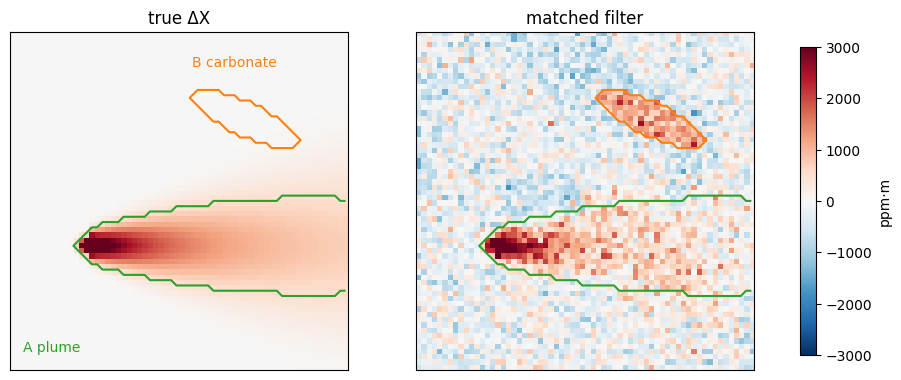

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, im) in zip(
    axes, (("true ΔX", delta_x), ("matched filter", mf)), strict=True
):
    h = ax.imshow(im / PPMM, cmap="RdBu_r", vmin=-3000, vmax=3000)
    ax.contour(mask_a, levels=[0.5], colors="C2")
    ax.contour(mask_b, levels=[0.5], colors="C1")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(h, ax=axes, shrink=0.8, label="ppm·m")
axes[0].text(2, 60, "A plume", color="C2")
axes[0].text(34, 6, "B carbonate", color="C1")
plt.show()

The matched filter flags both, and scores the carbonate patch B higher on average than the plume A, whose mask includes the faint tail.

## 3. Vetting the two candidates

radtrax's `AbsorptionWindow` here fits the nine absorbing bands and pairs on the 30 others. [`vet_candidate`](xref:api#plumax.vetting.vet_candidate) takes the seeds ([`select_seeds`](xref:api#plumax.vetting.select_seeds)), the background pool ([`background_pool`](xref:api#plumax.vetting.background_pool): every pixel within 16 pixels of the seeds' bounding box, outside both candidates, with a matched-filter score under twice its noise), pairs the two sets one to one with radtrax's `pair_pixels`, and fits the ratio.

In [8]:
window = AbsorptionWindow(
    "CH4",
    fit_nm=((2290.0, 2360.0),),
    absorbing_nm=((2290.0, 2360.0),),
    mf_background_mol_m2=2 * mf_sigma,
)
results = {}
for name, m in (("A", mask_a), ("B", mask_b)):
    results[name] = vet_candidate(
        L, mf, m, WL, E_TABLE, DELTA_GRID, window, exclude=masks, box=16
    )
    r = results[name]
    print(
        f"{name}: ΔX̂ = {float(r.delta) / PPMM:,.0f} ppm·m, "
        f"D_norm = {float(r.d_norm):.2f}, {r.n_pairs} pairs"
    )

A: ΔX̂ = 1,741 ppm·m, D_norm = 0.14, 64 pairs


B: ΔX̂ = 0 ppm·m, D_norm = 1.00, 54 pairs


A fits as methane with $D_{\text{norm}}$ well below 0.3. B fits at $\widehat{\Delta X} = 0$: the continuum takes the carbonate's smooth dip, nothing methane-shaped is left, and $D_{\text{norm}} \approx 1$. A's column is below the truth over its seed pixels for two reasons: the fit returns the column of the mean transmittance, not the mean column (the transmittance is convex in $\Delta X$), and paired surfaces never match exactly.

In [9]:
seeds_a = select_seeds(mf, mask_a)
pool_a = background_pool(
    mf, seeds_a, threshold=window.mf_background_mol_m2, exclude=masks, box=16
)
i_in, _ = pair_pixels(
    L, np.flatnonzero(seeds_a), np.flatnonzero(pool_a), window.pairing_bands(WL)
)
truth_a = delta_x.ravel()[i_in].mean()
print(
    f"A: truth over its kept pixels {truth_a / PPMM:,.0f} ppm·m; the fit recovers "
    f"{100 * float(results['A'].delta) / truth_a:.0f} %"
)
fit_lin = fit_transmittance(results["A"].ratio, E_LIN, DELTA_GRID, CENTERS_NM)
print(f"A with a constant coefficient: {float(fit_lin.delta) / PPMM:,.0f} ppm·m")

A: truth over its kept pixels 1,865 ppm·m; the fit recovers 93 %
A with a constant coefficient: 1,691 ppm·m


## 4. A null from the same scene

The honest null is this scene's clutter with no plume. [`null_masks`](xref:api#plumax.vetting.null_masks) draws 100 copies of each mask, rotated and translated off both candidates; each is vetted exactly as the candidate, and [`null_pvalue`](xref:api#plumax.vetting.null_pvalue) gives $\hat p$, the fraction that score at or below it.

In [10]:
key = jax.random.key(0)
null_scores = {}
for name, m in (("A", mask_a), ("B", mask_b)):
    key, sub = jax.random.split(key)
    copies = null_masks(m, 100, key=sub, exclude=masks)
    null_scores[name] = np.array(
        [
            float(
                vet_candidate(
                    L, mf, c, WL, E_TABLE, DELTA_GRID, window, exclude=masks, box=16
                ).d_norm
            )
            for c in copies
        ]
    )
    p_hat = null_pvalue(float(results[name].d_norm), null_scores[name])
    q05, q50 = np.quantile(null_scores[name], [0.05, 0.5])
    print(
        f"{name}: p̂ = {p_hat:.2f}; null D_norm 5th percentile {q05:.2f}, "
        f"median {q50:.2f}, {int((null_scores[name] < 0.3).sum())} of 100 below 0.3"
    )

A: p̂ = 0.00; null D_norm 5th percentile 0.47, median 0.79, 0 of 100 below 0.3


B: p̂ = 0.45; null D_norm 5th percentile 0.49, median 1.00, 1 of 100 below 0.3


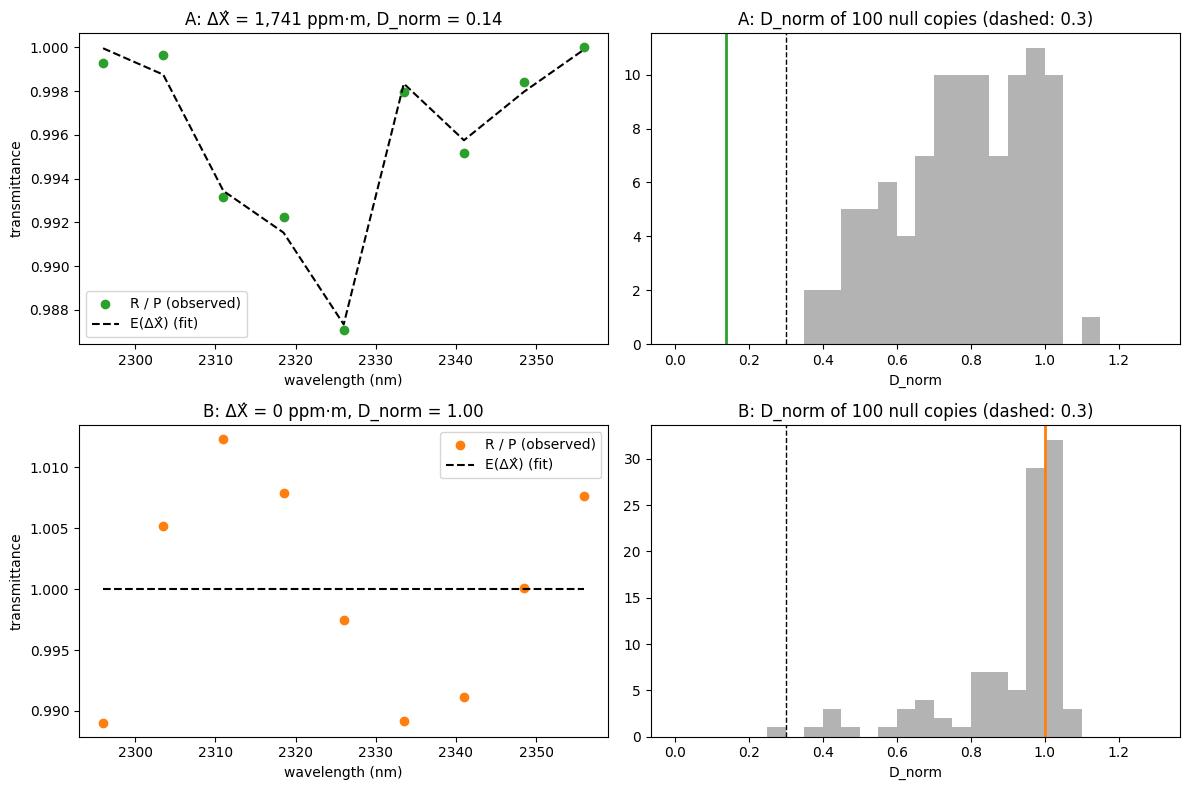

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, name in enumerate(("A", "B")):
    r = results[name]
    ax = axes[row, 0]
    ax.scatter(
        CENTERS_NM,
        r.ratio / r.fit.continuum,
        color=f"C{2 - row}",
        label="R / P (observed)",
    )
    ax.plot(CENTERS_NM, r.fit.transmittance, "k--", label="E(ΔX̂) (fit)")
    ax.set_title(
        f"{name}: ΔX̂ = {float(r.delta) / PPMM:,.0f} ppm·m, "
        f"D_norm = {float(r.d_norm):.2f}"
    )
    ax.set_xlabel("wavelength (nm)")
    ax.set_ylabel("transmittance")
    ax.legend()
    ax = axes[row, 1]
    ax.hist(null_scores[name], bins=np.linspace(0, 1.3, 27), color="0.7")
    ax.axvline(float(r.d_norm), color=f"C{2 - row}", lw=2)
    ax.axvline(0.3, color="k", ls="--", lw=1)
    ax.set_title(f"{name}: D_norm of 100 null copies (dashed: 0.3)")
    ax.set_xlabel("D_norm")
fig.tight_layout()
plt.show()

## Summary

- The matched filter scored the carbonate patch above the plume; the spectral fit reversed the order, accepting A and finding no methane in B.
- The transmittance comes from radtrax's forward model for the scene's own geometry and water vapour, so the curve of growth is built in; a constant coefficient biases strong plumes low.
- $D_{\text{norm}}$ thresholds depend on the window and the continuum's degree (this scene has 9 bands, EMIT's window 46), so report the scene-null $\hat p$ with every score and set the threshold per sensor on real scenes.
- Vetting's $\widehat{\Delta X}$ is a score, not a retrieval: the column for an emission rate comes from a per-pixel retrieval of the vetted plume.